## Importing Data

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams['text.usetex'] = True

H_P1 = pd.read_csv("Data//Standardised_IDs//HarrisPartI.csv")        
H_P2 = pd.read_csv("Data//Standardised_IDs//HarrisPartII.csv")        
H_P3 = pd.read_csv("Data//Standardised_IDs//HarrisPartIII.csv")         
V_T2 = pd.read_csv("Data//Standardised_IDs//vandenBerg_table2.csv")        
K_21 = pd.read_csv("Data//Standardised_IDs//Krause21.csv")  
G_HB = pd.read_csv("Data//Standardised_IDs//GaiaHB.csv")  
LE_G = pd.read_csv("Data//Standardised_IDs//LE_clusters.csv")  
HVK_Met = pd.read_csv("Data//MetalicityMerge//MergedMetalicities.csv")  

In [3]:
df = pd.merge(G_HB, H_P3,on="ID",how="outer")
df = pd.merge(df,HVK_Met,on="ID",how="outer")
df = pd.merge(df,LE_G,on="ID",how="left")
df["LE_group"] = df["LE_group"].fillna(False).astype(bool)
df['FeH'] = df['[FeH]_WtdAvg']
df['Age'] = df['Age']

###

## Compute Energy and Angular Momentum
### Here we use the gaalctic potential model and velocites from the Gaia EDR3 dataset

In [4]:
from galpy.potential import (MiyamotoNagaiPotential, NFWPotential, PowerSphericalPotentialwCutoff,
                             evaluatePotentials, vcirc, turn_physical_off)

R0, VC0 = 8.0, 235.0   # Belokurov paper values

pot = [PowerSphericalPotentialwCutoff(alpha=1.8, rc=1.9/8, normalize=0.05),   # bulge
       MiyamotoNagaiPotential(a=3/8, b=0.28/8, normalize=0.6),                # disc
       NFWPotential(conc=19.5, mvir=1.0, H=70., Om=0.3, overdens=200., wrtcrit=False, ro=R0, vo=VC0)]  # halo
turn_physical_off(pot)
pot = [p / vcirc(pot, 1., quantity=False)**2 for p in pot]   # rescale so vcirc(R0) = 235 km/s

x, y, z = df['X'].values, df['Y'].values, df['Z'].values
vx, vy, vz = df['U'].values, df['V'].values, df['W'].values
ok = np.isfinite(x*y*z*vx*vy*vz)
phi = np.full(len(df), np.nan)
phi[ok] = (evaluatePotentials(pot, np.hypot(x, y)[ok]/R0, z[ok]/R0)
           - evaluatePotentials(pot, 1e6, 0.)) * VC0**2

# Compute the energy and angular momentum
df['E']  = (0.5*(vx**2 + vy**2 + vz**2) + phi) / 1e5   # units of 1e5 km^2/s^2 ?
df['Lz'] = (x*vy - y*vx) / 1e3                        # units of 1e3 kpc km/s
df['Lx'] = (y*vz - z*vy) / 1e3
df['Ly'] = (z*vx - x*vz) / 1e3
df['Lperp'] = np.hypot(df['Lx'], df['Ly'])


df['V_phi'] = (x*vy - y*vx) / np.hypot(x, y) 

In [5]:
def E_boundary(Lz):
    # from Belokurov & Kravtsov, the accreted/insitu boundary curve
    Lz = np.asarray(Lz, dtype=float)
    return np.select([Lz < -0.58, Lz <= 0.58],
                     [-1.3 + 0*Lz, -1.4 + 0.3*Lz**2],
                     default=-1.325 + 0.075*Lz**2)

df['Accreted?'] = df['E'] > E_boundary(df['Lz'])   # True -> accreted

###
### Plot the E - Lz graph together with the boundary from the Belokurov paper

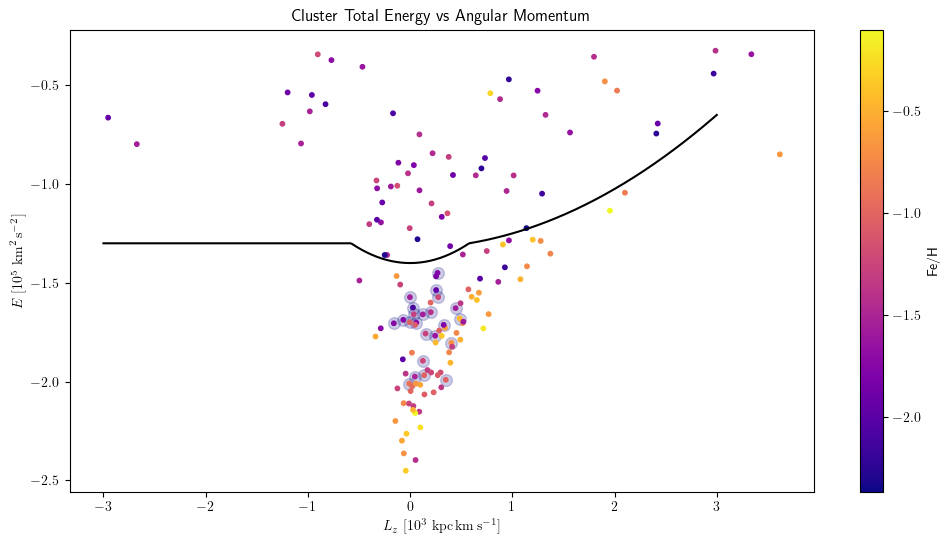

In [6]:
has_FeH = df['FeH'].notna()
plt.figure(figsize=[12, 6])
plt.scatter(df.loc[(df['LE_group'] == True) & has_FeH, 'Lz'], -np.abs(df.loc[(df['LE_group'] == True) & has_FeH, 'E']), alpha=0.2, c="navy", s=71)
plt.scatter(df.loc[has_FeH, 'Lz'], -np.abs(df.loc[has_FeH, 'E']), c=df.loc[has_FeH, 'FeH'], cmap="plasma", s=10)

Lz_grid = np.linspace(-3, 3, 500)
plt.plot(Lz_grid, E_boundary(Lz_grid), 'k-')

plt.title('Cluster Total Energy vs Angular Momentum')
#plt.yscale('log')
plt.xlabel(r'$L_z\ [10^3\ \mathrm{kpc}\,\mathrm{km}\,\mathrm{s}^{-1}]$')
plt.ylabel(r'$E\ [10^5\ \mathrm{km}^2\,\mathrm{s}^{-2}]$')
plt.colorbar().set_label('Fe/H')

### Around 2/3 of the clusters are In-situ

In [7]:
df.loc[df['Accreted?'] == True, 'Accreted?'].count()

61

In [8]:
df.loc[df['Accreted?'] == False, 'Accreted?'].count()

111

#### How many of the "in-situ" ones are in the LE group?

In [9]:
df.loc[(df['Accreted?'] == False) & (df['LE_group'] == True), 'Accreted?'].count()

24

###
### How does the obtained Accreted/In-situ classification affect the Age-Metallicity relation in the clusters?

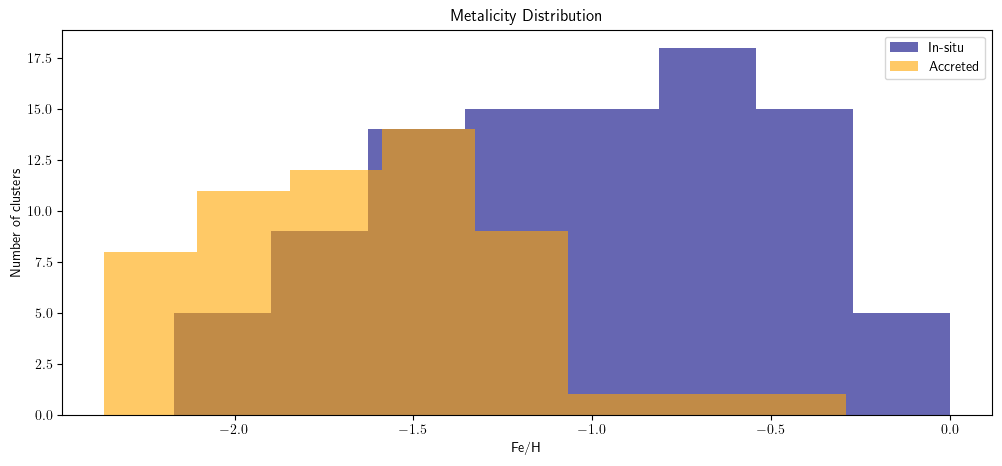

In [10]:
plt.figure(figsize=[12, 5])

plt.hist(df.loc[df['Accreted?'] == 0,'FeH'], bins=8, label='In-situ', color="navy", alpha=0.6)
plt.hist(df.loc[df['Accreted?'] == 1,'FeH'], bins=8, label='Accreted', color="orange", alpha=0.6)
plt.title('Metalicity Distribution')
plt.xlabel('Fe/H')
plt.ylabel('Number of clusters')
plt.legend()

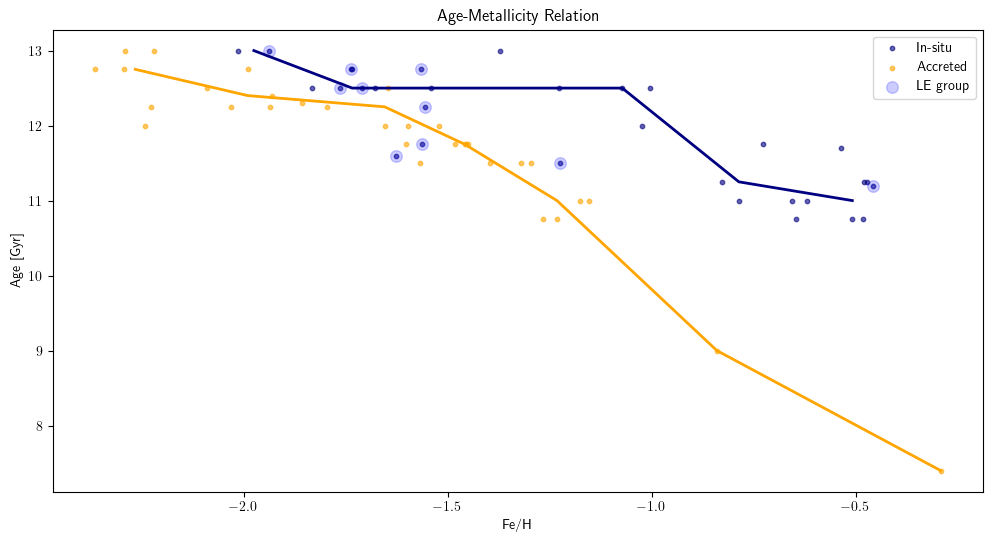

In [11]:
bins = np.arange(-2.5, 1, 0.3)

fig, ax = plt.subplots(figsize=(12, 6))
for flag, col, name in [(False, 'navy', 'In-situ'), (True, 'orange', 'Accreted')]:
    sub = df[df['Accreted?'] == flag].dropna(subset=['FeH', 'Age', 'E'])
    ax.scatter(sub['FeH'], sub['Age'], s=10, c=col, alpha=0.6, label=name)

    g = sub.groupby(pd.cut(sub['FeH'], bins), observed=True)
    med = g.agg(FeH=('FeH', 'median'), Age=('Age', 'median'), n=('Age', 'size'))
    ax.plot(med['FeH'], med['Age'], '-', c=col, lw=2, ms=5, mec='k')

plt.scatter(df.loc[df['LE_group'], 'FeH'], df.loc[df['LE_group'], 'Age'], s=70, alpha=0.2, c="blue", label='LE group')
ax.set(xlabel='Fe/H', ylabel='Age [Gyr]', title='Age-Metallicity Relation')
ax.legend()

###
### The in-situ clusters generally form in the bulge where the star density is very high
### Accreted clusters can be accreted anywhere and will be present throughout the halo, potentially quite high above the disk

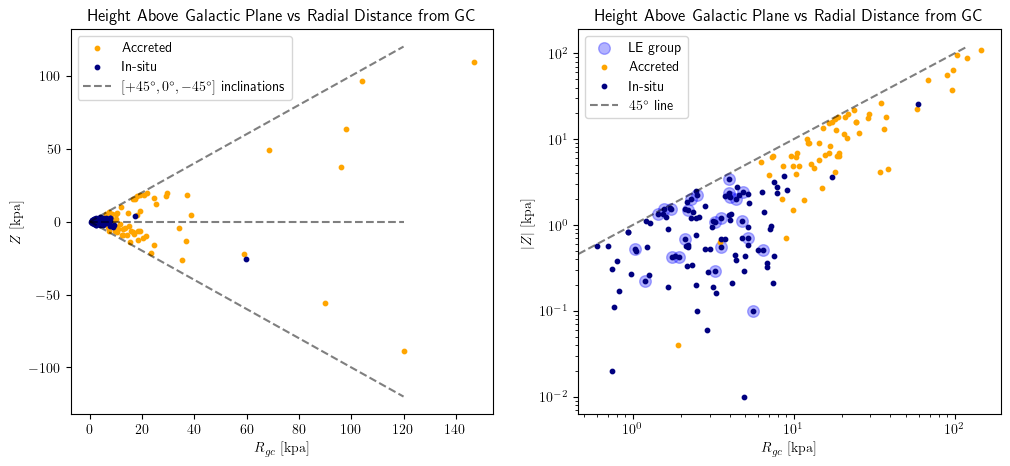

In [12]:
plt.figure(figsize=[12, 5])
plt.subplot(1, 2, 1)
plt.scatter(df.loc[df['Accreted?'], 'Rgc'], (df.loc[df['Accreted?'], 'Z']), c="orange", s=10, label = 'Accreted')
plt.scatter(df.loc[~df['Accreted?'], 'Rgc'], (df.loc[~df['Accreted?'], 'Z']), c="navy", s=10, label = 'In-situ')

plt.title('Height Above Galactic Plane vs Radial Distance from GC')
#plt.yscale('log')
plt.xlabel(r'$R_{gc}\ [\mathrm{kpa}]$')
plt.ylabel(r'$Z\ \space [\mathrm{kpa}]$')

plt.plot([0,120],[0,120],"k",linestyle="--",label=r"$[+45^\circ,0^\circ,-45^\circ]$ inclinations",alpha=0.5)
plt.plot([0,120],[0,0],"k",linestyle="--",alpha=0.5)
plt.plot([0,120],[0,-120],"k",linestyle="--",alpha=0.5)
plt.legend()

plt.subplot(1, 2, 2)
plt.scatter(df.loc[df['LE_group'], 'Rgc'], np.abs(df.loc[df['LE_group'], 'Z']), c="blue", s=70, alpha=0.3, label = 'LE group')
plt.scatter(df.loc[df['Accreted?'], 'Rgc'], np.abs(df.loc[df['Accreted?'], 'Z']), c="orange", s=10, label = 'Accreted')
plt.scatter(df.loc[~df['Accreted?'], 'Rgc'], np.abs(df.loc[~df['Accreted?'], 'Z']), c="navy", s=10, label = 'In-situ')

plt.title('Height Above Galactic Plane vs Radial Distance from GC')
#plt.yscale('log')
plt.xlabel(r'$R_{gc}\ [\mathrm{kpa}]$')
plt.ylabel(r'$|Z|\ \space [\mathrm{kpa}]$')

plt.yscale("log")
plt.xscale("log")
#plt.xlim(0.01,200)
#plt.ylim(0.01,200)
plt.plot([0,120],[0,120],"k",linestyle="--",label=r"$45^\circ$ line",alpha=0.5)
#plt.plot([0,120],[0,10.5],"k",linestyle="--",label=r"$5^\circ$ line",alpha=0.5)

plt.legend()

###
### Tangential velocity over radial distance. In-situ clusters are mostly in the halo and rotate quite fast (mostly co-rotating with the galaxy).

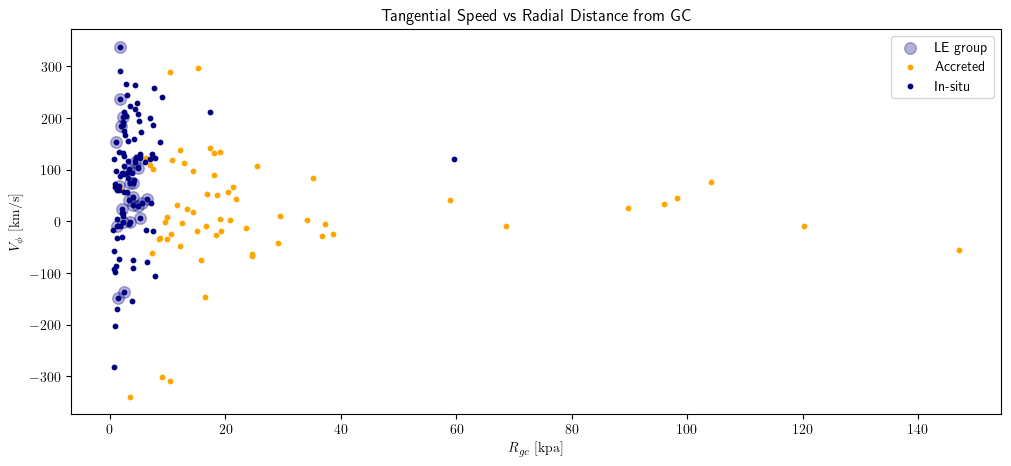

In [13]:
has_FeH = df['FeH'].notna()
plt.figure(figsize=[12, 5])

plt.scatter(df.loc[ df['LE_group'], 'Rgc'], df.loc[df['LE_group'], 'V_phi'], c="navy", s=70, alpha=0.3, label = 'LE group')
plt.scatter(df.loc[df['Accreted?'], 'Rgc'], df.loc[df['Accreted?'], 'V_phi'], c="orange", s=10, label = 'Accreted')
plt.scatter(df.loc[~df['Accreted?'], 'Rgc'], df.loc[~df['Accreted?'], 'V_phi'], c="navy", s=10, label = 'In-situ')

plt.title('Tangential Speed vs Radial Distance from GC')
#plt.yscale('log')
plt.xlabel(r'$R_{gc}\ [\mathrm{kpa}]$')
plt.ylabel('$V_{\phi}\ [\mathrm{km/s}]$')
plt.legend()

###
### Radial Distribution and Tengential Velocity Distribution

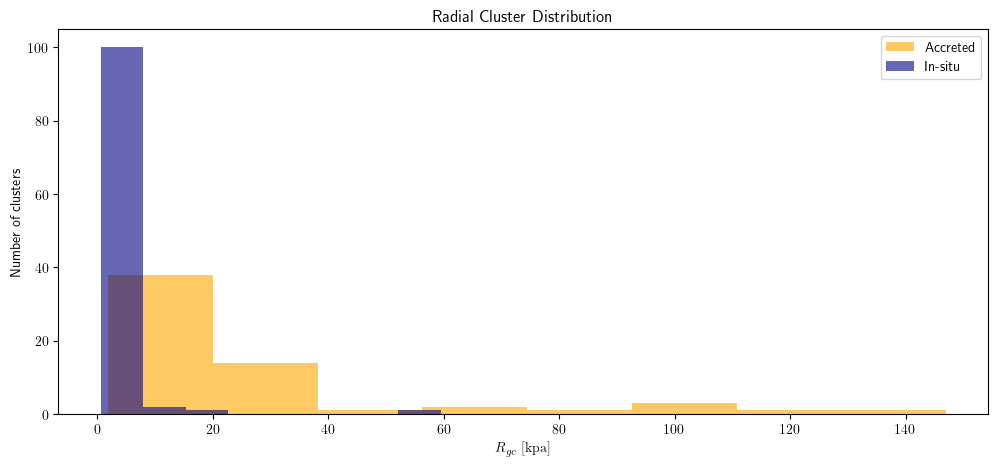

In [14]:
plt.figure(figsize=[12, 5])

plt.hist(df.loc[df['Accreted?'] == 1,'Rgc'], bins=8, label='Accreted', color="orange", alpha=0.6)
plt.hist(df.loc[df['Accreted?'] == 0,'Rgc'], bins=8, label='In-situ', color="navy", alpha=0.6)
plt.title('Radial Cluster Distribution')
plt.xlabel(r'$R_{gc}\ [\mathrm{kpa}]$')
plt.ylabel('Number of clusters')
plt.legend()

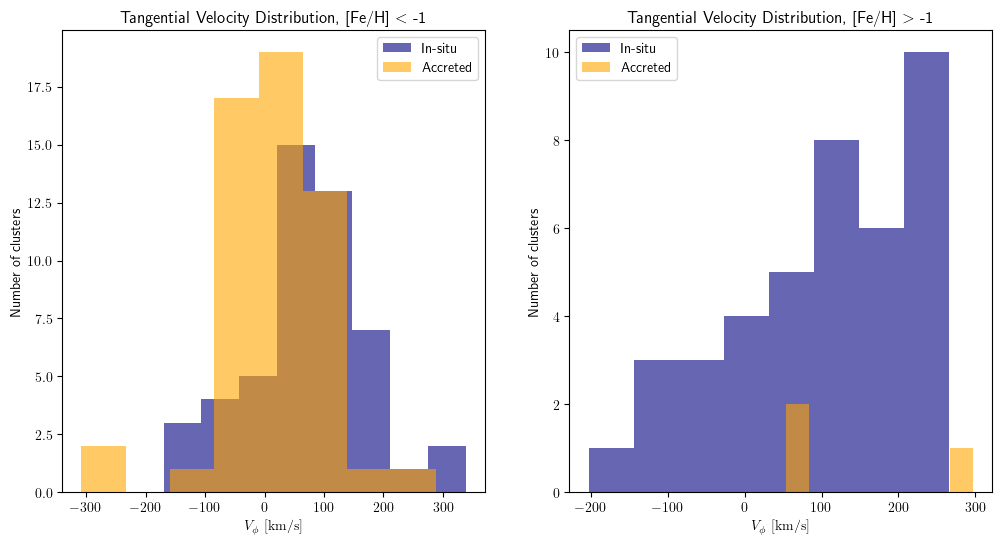

In [15]:
plt.figure(figsize=[12, 6])
plt.subplot(1, 2, 1)

plt.hist(df.loc[(df['Accreted?'] == 0)&(df['FeH'] < -1) ,'V_phi'], bins=8, label='In-situ', color="navy", alpha=0.6)
plt.hist(df.loc[(df['Accreted?'] == 1)&(df['FeH'] < -1),'V_phi'], bins=8, label='Accreted', color="orange", alpha=0.6)
plt.title('Tangential Velocity Distribution, [Fe/H] $<$ -1')
plt.xlabel(r'$V_{\phi}\ [\mathrm{km/s}]$')
plt.ylabel('Number of clusters')
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(df.loc[(df['Accreted?'] == 0)&(df['FeH'] > -1) ,'V_phi'], bins=8, label='In-situ', color="navy", alpha=0.6)
plt.hist(df.loc[(df['Accreted?'] == 1)&(df['FeH'] > -1),'V_phi'], bins=8, label='Accreted', color="orange", alpha=0.6)
plt.title('Tangential Velocity Distribution, [Fe/H] $>$ -1')
plt.xlabel(r'$V_{\phi}\ [\mathrm{km/s}]$')
plt.ylabel('Number of clusters')
plt.legend()

# Additional Figures:

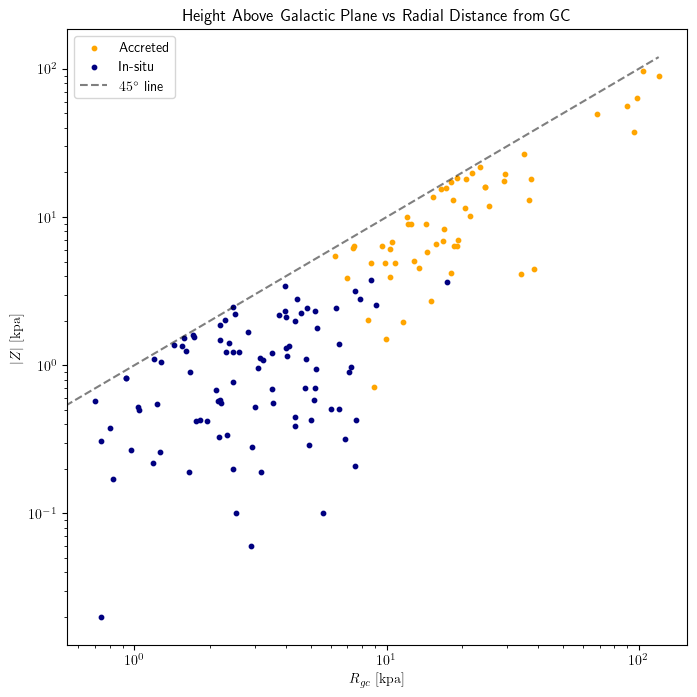

In [16]:
plt.figure(figsize=[8, 8])
plt.scatter(df.loc[has_FeH & df['Accreted?'], 'Rgc'], np.abs(df.loc[has_FeH & df['Accreted?'], 'Z']), c="orange", s=10, label = 'Accreted')
plt.scatter(df.loc[has_FeH & ~df['Accreted?'], 'Rgc'], np.abs(df.loc[has_FeH & ~df['Accreted?'], 'Z']), c="navy", s=10, label = 'In-situ')

plt.title('Height Above Galactic Plane vs Radial Distance from GC')
#plt.yscale('log')
plt.xlabel(r'$R_{gc}\ [\mathrm{kpa}]$')
plt.ylabel(r'$|Z|\ \space [\mathrm{kpa}]$')

plt.yscale("log")
plt.xscale("log")
#plt.xlim(0.01,200)
#plt.ylim(0.01,200)
plt.plot([0,120],[0,120],"k",linestyle="--",label=r"$45^\circ$ line",alpha=0.5)
#plt.plot([0,120],[0,10.5],"k",linestyle="--",label=r"$5^\circ$ line",alpha=0.5)

plt.legend()

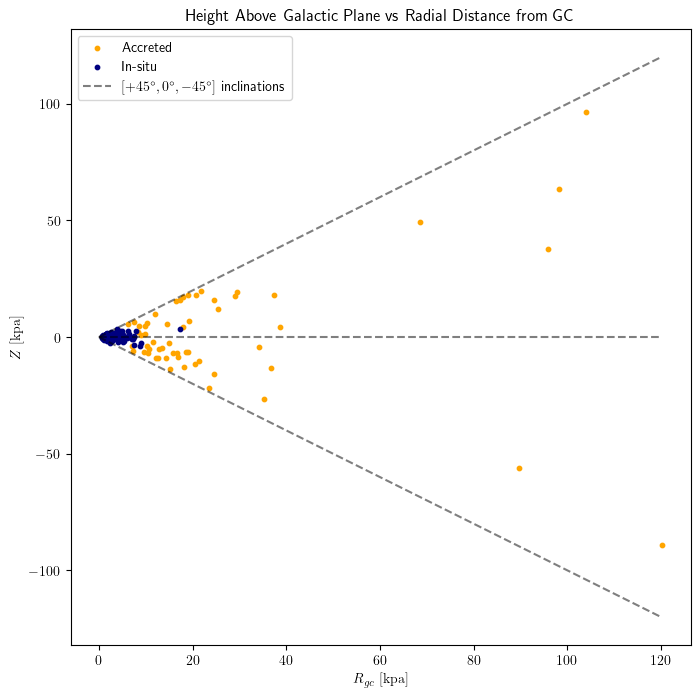

In [17]:
plt.figure(figsize=[8, 8])
plt.scatter(df.loc[has_FeH & df['Accreted?'], 'Rgc'], (df.loc[has_FeH & df['Accreted?'], 'Z']), c="orange", s=10, label = 'Accreted')
plt.scatter(df.loc[has_FeH & ~df['Accreted?'], 'Rgc'], (df.loc[has_FeH & ~df['Accreted?'], 'Z']), c="navy", s=10, label = 'In-situ')

plt.title('Height Above Galactic Plane vs Radial Distance from GC')
#plt.yscale('log')
plt.xlabel(r'$R_{gc}\ [\mathrm{kpa}]$')
plt.ylabel(r'$Z\ \space [\mathrm{kpa}]$')

#plt.yscale("log")
#plt.xscale("log")
#plt.xlim(0.01,200)
#plt.ylim(0.01,200)
plt.plot([0,120],[0,120],"k",linestyle="--",label=r"$[+45^\circ,0^\circ,-45^\circ]$ inclinations",alpha=0.5)
plt.plot([0,120],[0,0],"k",linestyle="--",alpha=0.5)
plt.plot([0,120],[0,-120],"k",linestyle="--",alpha=0.5)


plt.legend()

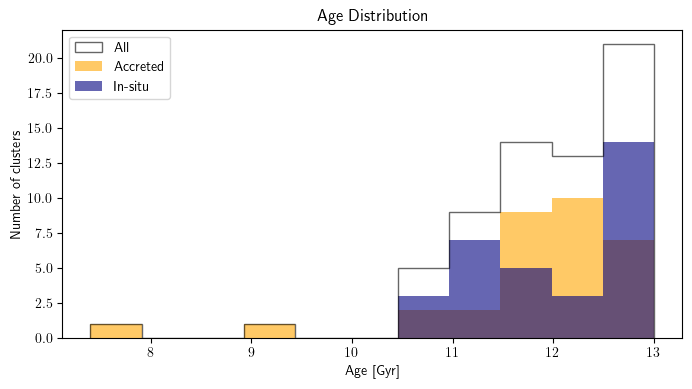

In [18]:
has_Age = df['Age'].notna()

def FreedmanDiaconis(Series):
    q1, q3 = np.percentile(Series, [25, 75])
    IQR = q3-q1
    h = 2*IQR*len(Series)**(-1/3)
    #print(h)
    MAX=max(df.loc[has_Age,"Age"])
    MIN=min(df.loc[has_Age,"Age"])
    nbins = (MAX-MIN)/h
    return round(nbins)


def HistogramBins(Series):
    nbins = FreedmanDiaconis(Series)
    bins = np.histogram(Series, bins=nbins)[1]
    return bins


bins = HistogramBins(df.loc[has_Age,"Age"])


plt.figure(figsize=[8, 4])

plt.hist(df['Age'],  bins=bins, label='All',histtype='step', edgecolor="k" ,fill=False, alpha=0.6)
plt.hist(df.loc[df['Accreted?'] == 1,'Age'], bins=bins, label='Accreted', color="orange", alpha=0.6)
plt.hist(df.loc[df['Accreted?'] == 0,'Age'], bins=bins, label='In-situ', color="navy", alpha=0.6)
#plt.hist(df.loc[df['LE_group'], 'Age'],  bins=bins, label=r'LE group (subset of in-situ)', edgecolor="k" ,hatch='///',fill=False)





plt.title('Age Distribution')
plt.xlabel('Age [Gyr]')
plt.ylabel('Number of clusters')
plt.legend()